Nama: Aulia Aziza
NIM: 24031554102
Kelas: 2024B

## 1.2 Pembuatan objek dan akses objek (arthur)

In [1]:
from neo4j import GraphDatabase, RoutingControl

In [2]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Password") 

In [3]:
def add_friend(driver, name, friend_name): #menerima driver, nama orang, dan nama temannya
    driver.execute_query(
        "MERGE (a:Person {name: $name}) " #mencari node berlabel person yang namanya sama
        "MERGE (friend:Person {name: $friend_name}) " 
        "MERGE (a)-[:KNOWS]->(friend)", #membuat relasi knows berarah dari a ke friend hanya jika belum ada
        name=name, friend_name=friend_name, database_="neo4j",
    ) 

In [4]:
def print_friends(driver, name): #mencetak dan menjalankan keseluruhan
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name " #mencari pola seorang person yang punya relasi knows ke seseorang
        "RETURN friend.name ORDER BY friend.name", 
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

In [5]:
with GraphDatabase.driver(URI, auth=AUTH) as driver: #menampilkan nama teman arthur berdasarkan abjad
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


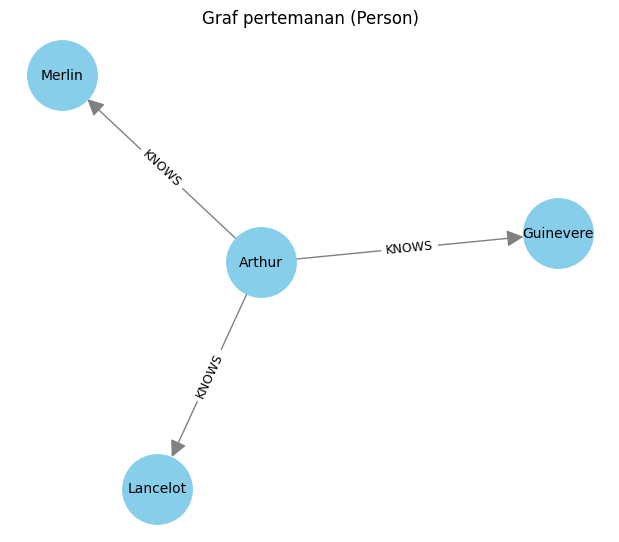

In [6]:
#graf arthur
import networkx as nx
import matplotlib.pyplot as plt

with GraphDatabase.driver(URI, auth=AUTH) as drv: #menjalankan add_friend lewat loop
    for teman in ["Guinevere", "Lancelot", "Merlin"]:
        add_friend(drv, "Arthur", teman)

    records, _, _ = drv.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(b:Person) RETURN a.name AS a, b.name AS b",
        database_="neo4j", routing_=RoutingControl.READ,
    ) #mengambil semua pasangan (pemilik relasi, teman)

G = nx.DiGraph() #graf berarah
for r in records:
    G.add_edge(r["a"], r["b"]) #menambah sisi dari a ke b

pos = nx.spring_layout(G, seed=42) #menghitung posisi gambar tiap node 

plt.figure(figsize=(6, 5))
nx.draw(G, pos, with_labels=True, node_color="skyblue", node_size=2500, font_size=10, arrows=True, arrowsize=25, edge_color="gray")
nx.draw_networkx_edge_labels(G, pos, edge_labels={e: "KNOWS" for e in G.edges()}, font_size=9)
plt.title("Graf pertemanan (Person)")
plt.savefig("images/graf_arthur.png", dpi=150)
plt.show()

## Pertanyaan Pendahuluan (Checkpoint)
1. Apa nama database yang digunakan pada tutorial ini?
Jawab: Nama database yang digunakan adlaah "neo4j", yaitu database default Neo4j. Nama ini diinisialisasi melalui parameter database_="neo4j".
     
2. Sebutkan akses lain (seperti sintaks DDL/DML CHYPER) yang dapat digunakan mengakses database lain dalam 1 instance!
Jawab: Pada cypher, perintah "USE namadb" (di dalam Neo4j browser: "use namadb"). Lalu pada driver python menggunakan parameter "database_="namadb"" pada execute_query atau seperti di contoh soal 1.3 yang tidak digunakan dalam skrip python ini (driver.session(database="system"). Serta administrasi database lewat database system ("CREATE DATABASE namadb", "SHOW DATABASES", "DROP DATABASE namadb").

3. Apa jenis graf pertemanan yang telah dibuat di sini?
Jawab: Graf yang dibuat disini adalah graf berarah (directed graph), terlihat dari -[:KNOWS]->. Tidak berbobot, karena tidak ada properti pada relasi di code. Serta merupakan simple graph, karena tidak memiliki loop (Arthur tidak KNOWS dirinya sendiri, relasinya selalu dari Arthur ke orang lain (Guinevere, Lancelot, Merlin)) dan tidak ada sisi ganda (MERGE membuat relasi hanya kalau belum ada).

In [7]:
with GraphDatabase.driver(URI, auth=AUTH) as driver: #reset database, data latihan saja, karena memori per transaksi neo4j tidak bisa untuk data sebesar itu
    driver.execute_query("MATCH (p:Person) DETACH DELETE p", database_="neo4j")
    print("Data latihan dihapus")

Data latihan dihapus


## 1.3 Koneksi ke Database Neo4j

Pada contoh, "argparse" dipakai agar parameter koneksi (user, password, alamat Bolt, folder sumber data) dapat diberikan lewat argumen terminal saat skrip dijalankan. Karena pengerjaan dilakukan di Jupyter Notebook, parameter tersebut didefinisikan langsung sebagai variabel (URI, AUTH, DB). Database yang dipakai adalah "neo4j", bukan "system".

In [8]:
import os, math
from collections import defaultdict #untuk rekomendasi
import numpy as np
import pandas as pd
import scipy.sparse as sp
from tqdm import tqdm
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from neo4j import GraphDatabase, RoutingControl

In [9]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "password")
DB = "neo4j"

try:
    driver = GraphDatabase.driver(URI, auth=AUTH)
    driver.verify_connectivity()
    print("Koneksi berhasil")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")

Koneksi berhasil


In [10]:
def run(query, **params): #menjalankan query baca, mengembalikan dataframe
    records, _, _ = driver.execute_query(query, parameters_=params, database_=DB, routing_=RoutingControl.READ)
    return pd.DataFrame([r.data() for r in records])

In [11]:
#cek rentang timestamp untuk menentukan periode
RAW = "data/events.csv"

if not os.path.exists(RAW):
    raise FileNotFoundError(f"File '{RAW}' tidak ditemukan")

df = pd.read_csv(RAW)
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms") #timestamp dalam milidetik

print("Jumlah baris :", len(df))
print("Rentang waktu:", df["dt"].min(), "-", df["dt"].max())
print("\nJumlah per jenis event:")
print(df["event"].value_counts())
print("\nJumlah baris per bulan:")
print(df.groupby(df["dt"].dt.to_period("M")).size())
df.head()

Jumlah baris : 2756101
Rentang waktu: 2015-05-03 03:00:04.384000 - 2015-09-18 02:59:47.788000

Jumlah per jenis event:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Jumlah baris per bulan:
dt
2015-05    590652
2015-06    610393
2015-07    697984
2015-08    553362
2015-09    303710
Freq: M, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,dt
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


## 2.1 No. 1-2 Pemilihan Periode dan Penyimpanan Data

Data interaksi dibagi secara temporal menjadi dua periode:
- P1 (fold training): dipakai untuk membangun graf Neo4j, matriks VSM, dan perhitungan similarity.
- P2 (fold testing): dipakai untuk evaluasi rekomendasi (Hit@5 dan NDCG@5).

P2 tidak dimasukkan ke graf agar tidak terjadi data leakage. Kolom timestamp berformat unix epoch dalam milidetik, sehingga dikonversi dengan "pd.to_datetime(..., unit="ms")" sebelum difilter. Hasil filter disimpan pada "data_p1/events.csv" dan "data_p2/events.csv".

Periode yang digunakan adalah P1 = ("2015-05-03", "2015-05-17") 3-17 mei 2015, dan P2 = ("2015-06-01", "2015-06-15") 1-15 juni 2015.

In [12]:
P1 = ("2015-05-03", "2015-05-17") #fold training
P2 = ("2015-06-01", "2015-06-15") #fold testing

In [13]:
def filter_period(d, start, end): #dua periode senagai pasangan awal dan akhir
    m = (d["dt"] >= pd.Timestamp(start)) & (d["dt"] < pd.Timestamp(end) + pd.Timedelta(days=1)) #ditambah satu hari karena timestamp 2015-05-17 berarti 17 mei pukul 00, jika tidak ditambah tanggal 17 mei tidak ikut
    return d.loc[m].copy()

cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
p1 = filter_period(df, *P1)[cols]
p2 = filter_period(df, *P2)[cols]

if len(p1) == 0 or len(p2) == 0:
    raise ValueError("Salah satu periode kosong")
    
for d in (p1, p2):
    d["transactionid"] = d["transactionid"].astype("Int64") #transactionid bertipe float karena ada NaN maka digunakan Int64 agar tersimpan 123

os.makedirs("data_p1", exist_ok=True)
os.makedirs("data_p2", exist_ok=True)
p1.to_csv("data_p1/events.csv", index=False)
p2.to_csv("data_p2/events.csv", index=False)

print("P1:", P1, ":", len(p1)) #output jumlah baris
print("P2:", P2, ":", len(p2))

P1: ('2015-05-03', '2015-05-17') : 296319
P2: ('2015-06-01', '2015-06-15') : 300563


In [14]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE") #id pada visitor harus unik
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

In [15]:
def import_batch(tx, batch): 
    cypher_query = """
    UNWIND $batch AS row 
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """ #memecah 10.000 baris (batch) menjadi baris-baris dengan nama row, untuk setiap baris cari node visitor dan item, untuk satu user nodenya tetap 1
    tx.run(cypher_query, batch=batch)

In [16]:
def import_csv(csv_file_path, batch_size=10_000):
    if not os.path.exists(csv_file_path):
        raise FileNotFoundError(f"File '{csv_file_path}' tidak ditemukan!")

    with open(csv_file_path, encoding="utf-8") as f:
        total_rows = sum(1 for _ in f) - 1
    total_chunks = (total_rows // batch_size) + 1

    with driver.session(database=DB) as session: #membuka session ke database neo4j, lalu membuat constraint
        create_constraints(session)

        print(f"Membaca file data dari: {csv_file_path}")
        chunks = pd.read_csv(csv_file_path, chunksize=batch_size, dtype={"transactionid": str}) #membaca file sepotong-sepotong (10.000 baris), membaca kolom itu sebagai teks supaya tidak berubah mwnjadi float

        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
            chunk["transactionid"] = chunk["transactionid"].fillna("")
            records = chunk.to_dict(orient="records") #mengubah potongan tabel menjadi daftar dictionary
            session.execute_write(import_batch, records)

    print("Proses impor berhasil")

In [17]:
jumlah_relasi = int(run("MATCH ()-[r]->() RETURN count(r) AS n")["n"][0])
if jumlah_relasi > 0:
    print(f"Graf sudah terisi ({jumlah_relasi:,} relasi), impor dilewati")
else:
    import_csv("data_p1/events.csv")

Graf sudah terisi (1,370,580 relasi), impor dilewati


## 2.1.3 Komposisi Subgraph

Penjelasan Cypher:
- MATCH (n) mengambil semua simpul pada graf.
- labels(n) mengembalikan label setiap simpul ("Visitor" atau "Item").
- count(*) adalah fungsi agregasi. Kolom non-agregat ("labels(n)") otomatis menjadi kunci pengelompokan, mirip "GROUP BY" pada SQL.
- ORDER BY jumlah DESC mengurutkan dari jumlah terbesar.
- MATCH ()-[r]->() mengambil semua relasi berarah, dan "type(r)" mengembalikan tipenya ("VIEWED", "ADDED_TO_CART", "BOUGHT").

Subgraph yang dibentuk dari periode P1 terdiri dari 2 jenis simpul dan 3 jenis relasi dengan rincian sebagai berikut:
- Simpul: Visitors (user) berjumlah 155.916, Item berjumlah 78.171, sehingga total simpul/node adalah 234.087.
- Relasi: "VIEWED" berjumlah 286.485, "ADDED_TO_CART" berjumlah 7.430, dan "BOUGHT" berjumlah 2.404, sehingga total relasi adalah 296.319.

Jumlah relasi (296.319) sama dengan jumlah baris data P1 yang diimpor, sehingga tidak ada data yang hilang maupun terduplikasi. Mayoritas relasi adalah "VIEWED" sedangkan "ADDED_TO_CART" dan "BOUGHT" jauh lebih sedikit, sesuai pola umum e-commerce bahwa lebih banyak orang melihat produk daripada membelinya

In [18]:
q_nodes = """
MATCH (n)
RETURN labels(n) AS label, count(*) AS jumlah
ORDER BY jumlah DESC
""" #menghitung jumlah node per label, lalu menampilkan hasilnya dari jumlah yang terbesar

q_rels = """
MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
RETURN type(r) AS relasi, count(*) AS jumlah
ORDER BY jumlah DESC
""" #menghitung jumlah relasi per jenis, lalu menampilkan hasilnya dari jumlah yang terbesar

print("Jenis dan jumlah simpul:")
print(run(q_nodes))
print("\nJenis dan jumlah relasi:")
print(run(q_rels))

Jenis dan jumlah simpul:
       label  jumlah
0  [Visitor]  155916
1     [Item]   78171

Jenis dan jumlah relasi:
          relasi  jumlah
0         VIEWED  286485
1  ADDED_TO_CART    7430
2         BOUGHT    2404


## 2.1 No. 4 Vector Space Modelling (VSM) pada User

VSM pada User dilakukan dengan merepresentasikan setiap user sebagai sebuah vektor yang menunjukkan interaksinya terhadap seluruh item. Bobot interaksi ditentukan berdasarkan tingkat intensitas minat user terhadap item, yaitu "VIEWED" = 1, "ADDED_TO_CART" = 3, dan "BOUGHT" = 5. Seluruh interaksi dengan pasangan user-item yang sama dijumlahkan sehingga diperoleh bobot interaksi untuk setiap pasangan tersebut. Berdasarkan hasil, karakteristik matriks VSM User adalah sebagai berikut:
- Shape matriks: 155.916, 78.171
- Dimensi vektor: 78.171
- Jumlah elemen nonzero (nnz): 231.267
- Density: 0,001897%
- Rata-rata elemen nonzero per baris: 1,48

Shape matriks menunjukkan bahwa terdapat 155.916 user yang direpresentasikan menggunakan vektor berdimensi 78.171, sesuai dengan jumlah item. Nilai nnz sebesar 231.267 menunjukkan jumlah elemen matriks yang memiliki nilai bukan nol. Sementara itu, density sebesar 0,001897% menunjukkan bahwa hanya sebagian sangat kecil dari seluruh elemen matriks yang berisi nilai interaksi. Rata-rata 1,48 elemen nonzero per baris menunjukkan bahwa setiap user memiliki rata-rata sekitar 1,48 item dengan bobot interaksi bukan nol dalam data yang dianalisis. Kondisi ini menunjukkan bahwa matriks VSM User bersifat sangat sparse karena sebagian besar user hanya berinteraksi dengan sebagian kecil item dibandingkan keseluruhan item yang tersedia.

## 2.1 No.5 Vector Space Modelling (VSM) pada Item

VSM pada Item dilakukan dengan merepresentasikan setiap item sebagai sebuah vektor yang menunjukkan interaksinya terhadap seluruh user. Representasi ini diperoleh dengan mentransposisikan matriks interaksi User, yaitu Xᵀ, sehingga baris merepresentasikan item dan kolom merepresentasikan user. Pembobotan interaksi tetap menggunakan nilai sama dengan vsm pada user. Berdasarkan hasil, karakteristik matriks VSM Item adalah sebagai berikut:
- Shape matriks: 78.171, 155.916
- Dimensi vektor: 155.916
- Jumlah elemen nonzero (nnz): 231.267
- Density: 0,001897%
- Rata-rata elemen nonzero per baris: 2,96

Shape matriks menunjukkan bahwa terdapat 78.171 item yang masing-masing direpresentasikan menggunakan vektor berdimensi 155.916, sesuai dengan jumlah user. Jumlah elemen nonzero dan density tetap sama dengan matriks VSM User karena proses transposisi hanya menukar posisi baris dan kolom tanpa mengubah nilai elemen matriks. Rata-rata 2,96 elemen nonzero per baris menunjukkan bahwa setiap item memiliki rata-rata sekitar 2,96 user dengan bobot interaksi bukan nol. Nilai ini lebih tinggi daripada rata-rata elemen nonzero per baris pada VSM User, yaitu 1,48. Hal tersebut menunjukkan bahwa interaksi pada data yang dianalisis rata-rata tersebar pada sekitar 2,96 user untuk setiap item, sedangkan setiap user memiliki sekitar 1,48 item yang berinteraksi dengannya.

In [19]:
W = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5} #bobot interaksi

edges = run("""
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS uid, i.itemId AS iid, type(r) AS rel, count(*) AS n
""") #mengambil semua interaksi dari neo4j
edges["w"] = edges["rel"].map(W) * edges["n"] #hitung bobot
edges = edges.groupby(["uid", "iid"], as_index=False)["w"].sum() #satukan per pasangan user, item

u_codes, u_idx = pd.factorize(edges["uid"]) #mengubah id menjadi nomor baris dan kolom
i_codes, i_idx = pd.factorize(edges["iid"])

X = sp.csr_matrix((edges["w"].values, (u_codes, i_codes)), shape=(len(u_idx), len(i_idx))) #membangun matrix x, hasilnya adalah vsm user dimana tiap baris adalah vektor satu user dengan dimensi sebanyak item
XT = X.T.tocsr() #menukar baris dan kolom

def describe(M, name):
    n_r, n_c = M.shape
    print(f"[{name}] shape={M.shape} | dimensi vektor={n_c} | nnz={M.nnz:,} "f"| density={M.nnz/(n_r*n_c):.6%} | rata2 nnz/baris={M.nnz/n_r:.2f}")

describe(X, "VSM User (baris=user, dimensi=item)")
describe(XT, "VSM Item (baris=item, dimensi=user)")

[VSM User (baris=user, dimensi=item)] shape=(155916, 78171) | dimensi vektor=78171 | nnz=231,267 | density=0.001897% | rata2 nnz/baris=1.48
[VSM Item (baris=item, dimensi=user)] shape=(78171, 155916) | dimensi vektor=155916 | nnz=231,267 | density=0.001897% | rata2 nnz/baris=2.96


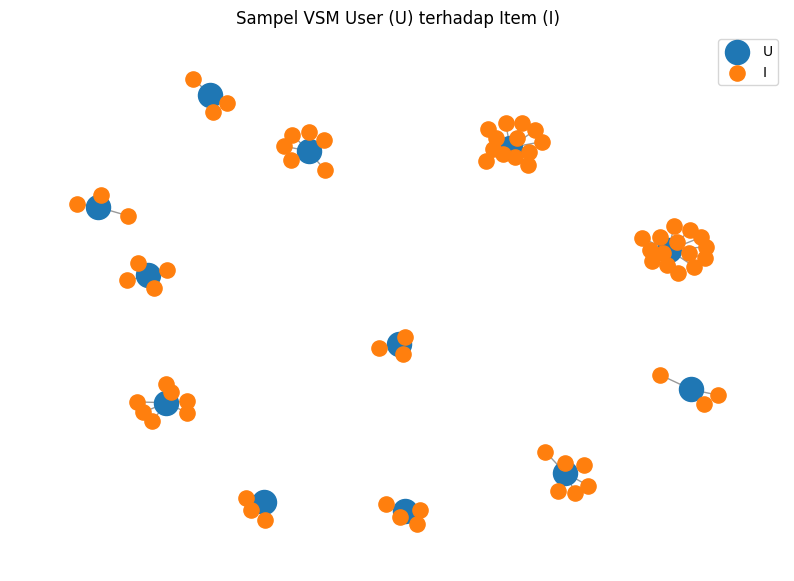

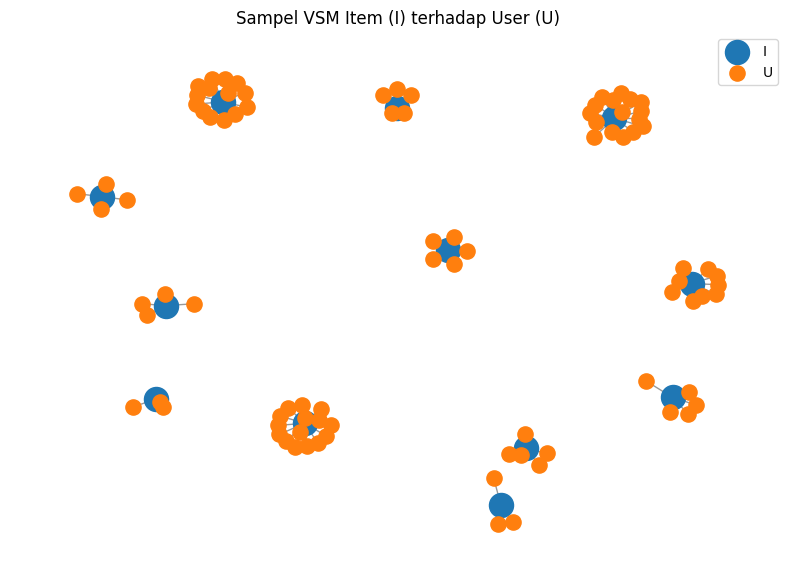

In [20]:
def plot_sample(M, row_ids, col_ids, tag_r, tag_c, n_rows=12, min_deg=3, seed=42, title=""): #visualisasi graf dari 12 baris acak matrix vsm
    rng = np.random.default_rng(seed)
    deg = np.diff(M.indptr) #jumlah elemen terisi per baris, lalu dihitung selisih tiap barisnya
    cand = np.where(deg >= min_deg)[0] #baris yang punya minimal 3 pasang
    pick = rng.choice(cand, size=min(n_rows, len(cand)), replace=False) #memilih 12 baris acak
    
    G = nx.Graph() #membangun graf dari baris terpilih
    for r in pick:
        a, b = M.indptr[r], M.indptr[r+1]
        for c, w in zip(M.indices[a:b], M.data[a:b]):
            G.add_edge(f"{tag_r}{row_ids[r]}", f"{tag_c}{col_ids[c]}", weight=w)
            
    rows = [n for n in G if n.startswith(tag_r)]
    pos = nx.spring_layout(G, seed=seed)
    plt.figure(figsize=(10, 7))
    nx.draw_networkx_nodes(G, pos, nodelist=rows, node_color="tab:blue", node_size=300, label=tag_r)
    nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G if n not in rows], node_color="tab:orange", node_size=120, label=tag_c)
    nx.draw_networkx_edges(G, pos, alpha=0.4)
    plt.title(title); plt.legend(); plt.axis("off"); plt.show()

plot_sample(X,  u_idx, i_idx, "U", "I", title="Sampel VSM User (U) terhadap Item (I)")
plot_sample(XT, i_idx, u_idx, "I", "U", title="Sampel VSM Item (I) terhadap User (U)")

Kedua plot menampilkan sampel acak sebanyak 12 baris dari matriks VSM, yang digambar sebagai graf. Sisi hanya menghubungkan simpul user dengan simpul item, tidak pernah dua simpul sejenis. Pada plot VSM User, setiap simpul biru (user) dikelilingi simpul oranye (item yang pernah diakses), sedangkan pada plot VSM Item peran warnanya dibalik, yaitu simpul biru (item) dikelilingi simpul oranye (user yang mengaksesnya). Seluruh kelompok berdiri sendiri dan tidak saling tersambung, 12 vektor sampel tidak berbagi pasangan sehingga tidak ada user atau item yang sama di antara kelompok tersebut. Hal ini menunjukkan bahwa matriks sangat sparse, karena setiap user hanya berinteraksi dengan sedikit item dari puluhan ribu item yang tersedia. Ukuran kelompok mencerminkan derajat node. Kelompok kecil adalah user dengan sedikit item (pada plot User), atau item yang jarang diakses (pada plot Item), sedangkan kelompok besar adalah user yang aktif atau item populer. Kelompok pada plot VSM Item cenderung lebih besar daripada plot VSM User, sejalan dengan rata-rata nnz per baris pada XT yang lebih besar daripada X, sehingga vektor item lebih padat dan lebih layak dibandingkan.

## 2.1 No. 6 Proyeksi yang Lebih Baik

Graf User-Item bersifat bipartit, sehingga dapat diproyeksikan menjadi graf User-User (dua user terhubung jika mengakses minimal satu item yang sama) atau graf Item-Item (dua item terhubung jika diakses oleh minimal satu user yang sama). Kedua proyeksi dibandingkan dari matriks interaksi biner dengan jumlah sisi dihitung sebagai jumlah pasangan, yaitu d(d−1)/2 untuk setiap perantara. Nilai ini merupakan batas atas, karena pasangan yang memiliki lebih dari satu perantara terhitung berulang.

Berikut perbandingan dari 2 proyeksi tersebut:
- Proyeksi user-user: 155.916 node, 1.539.089 edge/sisi, 155.916 x 155.916 ukuran matriks similarity
- Proyeksi item-item: 78.171 node, 1.123.622 edge/sisi, 78.171 x 78.171 ukuran matriks similarity

Proyeksi User-User memiliki node sekitar 2 kali lebih banyak, sisi yang lebih banyak, dan matriks similarity sekitar 4 kali lebih besar. Selain itu, rata-rata derajat per node pada proyeksi Item-Item (28,48) lebih tinggi daripada User-User (19,11), sehingga setiap item rata-rata terhubung dengan lebih banyak item lain dan informasi kemiripannya lebih kaya.

Kesimpulan: proyeksi item-item lebih efektif dan efisien. Dari sisi efisiensi, jumlah node, sisi, dan ukuran matriksnya lebih kecil sehingga hemat memori dan waktu komputasi. Dari sisi efektivitas, graf item-item lebih padat (0.0352) sehingga lebih banyak item yang memiliki tetangga untuk dibandingkan.

In [21]:
B = X.copy(); B.data[:] = 1 #matriks biner                   
deg_u = np.asarray(B.sum(axis=1)).ravel() #jumlah item per user     
deg_i = np.asarray(B.sum(axis=0)).ravel() #jumlah user per item

n_users, n_items = B.shape #jumlah node
edges_user_proj = (deg_i * (deg_i - 1) / 2).sum() #jumlah sisi, batas atas
edges_item_proj = (deg_u * (deg_u - 1) / 2).sum()

print(f"Proyeksi User-User: node={n_users:,} | sisi (batas atas)={edges_user_proj:,.0f} "f"| ukuran matriks={n_users:,} x {n_users:,}")
print(f"Proyeksi Item-Item: node={n_items:,} | sisi (batas atas)={edges_item_proj:,.0f} "f"| ukuran matriks={n_items:,} x {n_items:,}")

Proyeksi User-User: node=155,916 | sisi (batas atas)=1,539,089 | ukuran matriks=155,916 x 155,916
Proyeksi Item-Item: node=78,171 | sisi (batas atas)=1,123,622 | ukuran matriks=78,171 x 78,171


In [22]:
def ringkas(nama, n, sisi): #menghitung derajat dan density
    rata_derajat = 2 * sisi / n   
    density = sisi / (n * (n - 1) / 2)        
    return {"Proyeksi": nama, "Node": n, "Sisi": int(sisi),
            "Rata-rata derajat": round(rata_derajat, 2),
            "Density (%)": round(density * 100, 4)}
    
Pu = (B @ B.T).tocsr() #elemen (u,v) bukan nol jika user u dan v berbagi minimal 1 item
Pi = (B.T @ B).tocsr() #elemen (i,j) bukan nol jika item i dan j dilihat user yang sama

def sisi_unik(P):
    return (P.nnz - np.count_nonzero(P.diagonal())) // 2  #buang diagonal, bagi 2 karena matriks simetris

unik = pd.DataFrame([
    ringkas("User-User", n_users, sisi_unik(Pu)),
    ringkas("Item-Item", n_items, sisi_unik(Pi)),
])

print("\nBerdasarkan sisi unik (sebenarnya):")
print(unik.to_string(index=False))


Berdasarkan sisi unik (sebenarnya):
 Proyeksi   Node    Sisi  Rata-rata derajat  Density (%)
User-User 155916 1489900              19.11       0.0123
Item-Item  78171 1074261              27.48       0.0352


## 2.1 No. 7 Perhitungan Similarity pada Graf Proyeksi Item-Item

Berdasarkan analisis no. 6, perhitungan similarity dilakukan pada proyeksi Item-Item, karena proyeksi ini lebih kecil (78.171 node dibanding 155.916 pada User-User) sehingga lebih efisien. Dengan menggunakan metode cosine similarity, setiap item direpresentasikan sebagai vektor pada ruang berdimensi user (baris matriks Xᵀ dari no. 5). 

Similarity dihitung untuk seluruh pasangan item yang berbagi minimal satu user, menghasilkan 1.074.261 pasangan dari 78.171 item. Jumlah ini lebih kecil daripada batas atas 1.123.622 pada no. 6, karena pasangan yang memiliki lebih dari satu user perantara hanya dihitung satu kali.

Median (0,0867) jauh lebih kecil daripada rata-rata (0,2004), artinya distribusi condong ke kanan, sebagian besar pasangan kemiripannya rendah, dan hanya sebagian kecil yang tinggi. Nilai maksimum 1 menunjukkan ada pasangan item yang vektor usernya searah sempurna.

### 7a. Cypher untuk 5 record dengan similarity tertinggi

Record acuan ditentukan dengan aturan yang dapat direproduksi, yaitu item dengan jumlah user terbanyak pada P1 (itemId = 369447).

Penjelasan Cypher:
- "MATCH (a:Item {itemId: $ref})" mencari simpul item acuan. "$ref" adalah parameter yang diisi dari Python.
- "-[s:SIMILAR_TO]-(b:Item)" mengikuti relasi "SIMILAR_TO" ke item lain. Relasi diberi nama "s" agar propertinya dapat dibaca. Tanda tanpa panah dipakai karena setiap pasangan disimpan satu arah (berdasarkan urutan indeks matriks) sedangkan cosine bersifat simetris, sehingga relasi harus dibaca dari kedua arah.
- "RETURN a.itemId AS acuan, b.itemId AS mirip, s.score AS cosine" menampilkan item acuan, item yang mirip, dan nilai cosine.
- "ORDER BY s.score DESC LIMIT 5" mengurutkan dari similarity terbesar dan mengambil lima teratas.

hasilnya, item 356129 adalah yang paling mirip dengan item acuan, irisan user yang mengakses kedua item ini paling besar. Kelima nilai berada di atas kuartil 3 (0,2582), sehingga termasuk 25% pasangan dengan kemiripan tertinggi. Namun nilai tertingginya hanya sekitar 0,53, jadi bahkan tetangga terdekat dari item terpopuler pun kemiripannya tergolong sedang, bukan hampir identik.

### 7b. Menuliskan kembali nilai similarity ke graf

Nilai similarity ditulis sebagai relasi baru "SIMILAR_TO" antar simpul "Item", dengan properti "score" (nilai cosine) dan "method" ("cosine").

Penjelasan Cypher:
- "UNWIND $rows AS r" memecah daftar pasangan item (dikirim dari Python per 5.000 baris) menjadi baris-baris yang diproses satu per satu.
- "MATCH" mencari dua simpul item yang sudah ada di graf.
- "MERGE" membuat relasi "SIMILAR_TO" hanya jika belum ada, sehingga penulisan ulang tidak menghasilkan relasi ganda.
- "SET" menyimpan nilai cosine dan nama metodenya sebagai properti relasi.

Hasil query (jumlah relasi per jenis pada graf):

| Jenis relasi | Jumlah |
|---|---|
| SIMILAR_TO | 1.074.261 |
| VIEWED | 286.485 |
| ADDED_TO_CART | 7.430 |
| BOUGHT | 2.404 |
| Total | 1.370.580 |

Jumlah "SIMILAR_TO" di Neo4j (1.074.261) sama dengan jumlah pasangan hasil perhitungan Python, sehingga seluruh nilai similarity telah tertulis lengkap dan tanpa duplikat. Jumlah relasi User-Item (296.319) tidak berubah, jadi penulisan similarity hanya menambah relasi antar item pada graf yang sudah ada.

In [23]:
Xi = normalize(XT) #tiap baris item dinormalisasi
S = (Xi @ Xi.T).tocoo() #cosine setiap pasangan item yang berbagi minimal 1 user

m = S.row < S.col #buang diagonal dan duplikat simetris
sim = pd.DataFrame({
    "a": np.asarray(i_idx)[S.row[m]],
    "b": np.asarray(i_idx)[S.col[m]],
    "score": np.clip(S.data[m], 0, 1), 
})

print("Jumlah pasangan item:", len(sim))
print(sim["score"].describe())

Jumlah pasangan item: 1074261
count    1.074261e+06
mean     2.003793e-01
std      2.573831e-01
min      2.996180e-04
25%      3.005565e-02
50%      8.671100e-02
75%      2.581989e-01
max      1.000000e+00
Name: score, dtype: float64


In [24]:
n_sim = len(sim) #jumlah pasangan item pada tabel sim
ada = int(run("MATCH ()-[r:SIMILAR_TO]->() RETURN count(r) AS n")["n"][0]) #menghitung jumlah relari SIMILAR_TO yang ada di neo4j
print(f"SIMILAR_TO di Neo4j: {ada:,} pasangan pada sim: {n_sim:,}")

q = """
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[x:SIMILAR_TO]->(b)
SET x.score = r.score, x.method = 'cosine'
""" #memecah daftar pasangan, mencarikan dua simpul item, membuat relasi SIMILAR TO dari a ke b hanya jika belum ada

if ada == n_sim:
    print("SIMILAR_TO sudah lengkap")
elif ada < n_sim:
    print("SIMILAR_TO belum lengkap")
    batch = 5000
    for k in tqdm(range(0, n_sim, batch), desc="SIMILAR_TO"):
        rows = sim.iloc[k:k+batch].to_dict("records")
        driver.execute_query(q, parameters_={"rows": rows}, database_=DB)
else:
    print("Jumlah SIMILAR_TO melebihi seharusnya")

print(run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY jumlah DESC"))

SIMILAR_TO di Neo4j: 1,074,261 pasangan pada sim: 1,074,261
SIMILAR_TO sudah lengkap
          relasi   jumlah
0     SIMILAR_TO  1074261
1         VIEWED   286485
2  ADDED_TO_CART     7430
3         BOUGHT     2404


In [25]:
ref_item = int(i_idx[np.argmax(np.asarray((XT != 0).sum(axis=1)).ravel())]) #item terpopuler
print("Item acuan:", ref_item)

q_top5 = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]-(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, s.score AS cosine
ORDER BY s.score DESC
LIMIT 5
""" #mencari node item acuan, mengikuti relasi SIMILAR TO ke item lain, lalu menampilkan lima teratas item acuan, item yang mirip, dan nilai cosine dari yang terbesar

print(run(q_top5, ref=ref_item))

Item acuan: 369447
    acuan   mirip    cosine
0  369447  356129  0.526616
1  369447  274435  0.494426
2  369447  272327  0.387239
3  369447  379935  0.381406
4  369447  224582  0.366223


## 2.1 No. 8 Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

Kondisi graf dibandingkan menggunakan item acuan yang sama dengan no. 7, yaitu itemId = 369447 (item dengan jumlah user terbanyak pada P1).

### Sebelum similarity

Graf hanya berisi relasi antara user dan item ("VIEWED", "ADDED_TO_CART", "BOUGHT"), sehingga berbentuk graf bipartit. Tidak ada relasi antar item.

Penjelasan Cypher:
- "p = ..." menyimpan seluruh jalur (path) agar dapat ditampilkan sebagai graf.
- Tanda "|" pada tipe relasi berarti salah satu dari ketiga jenis relasi.
- "LIMIT 25" membatasi jumlah jalur agar graf terbaca, karena item acuan memiliki banyak user.

### Sesudah similarity

Muncul relasi baru "SIMILAR_TO" yang menghubungkan item acuan dengan item-item yang mirip, lengkap dengan nilai cosine pada properti "score".

Penjelasan Cypher:
- "-[s:SIMILAR_TO]-" tanpa panah mencocokkan relasi dari kedua arah, karena setiap pasangan disimpan satu kali sedangkan cosine bersifat simetris.
- "WITH p, s ORDER BY s.score DESC LIMIT 10" mengurutkan jalur berdasarkan nilai cosine, lalu mengambil 10 teratas agar graf terbaca.

### Perbandingan jumlah relasi

Selisih total relasi adalah 1.074.261, sama dengan jumlah relasi "SIMILAR_TO" yang ditambahkan. Jumlah simpul tidak berubah, yaitu 155.916 Visitor dan 78.171 Item (total 234.087), karena perhitungan similarity hanya menambahkan relasi dan tidak membuat simpul baru. Relasi user-item juga tidak berubah.

In [27]:
print("SEBELUM similarity (graf User-Item)")
print(f"""MATCH p = (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {{itemId: {ref_item}}})
RETURN p LIMIT 25""") #mencari maksimal 25 jalur dari user ke item acuan lewat relasi

print("\nSESUDAH similarity (muncul relasi SIMILAR_TO)")
print(f"""MATCH p = (a:Item {{itemId: {ref_item}}})-[s:SIMILAR_TO]-(b:Item)
WITH p, s ORDER BY s.score DESC LIMIT 10
RETURN p""") #mencari jalur dari item acuan ke item-item lain lewat relasi SIMILAR TO tanpa memandang arah, manampilkan 10 teratas berdasarkan cosine terbesar

SEBELUM similarity (graf User-Item)
MATCH p = (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: 369447})
RETURN p LIMIT 25

SESUDAH similarity (muncul relasi SIMILAR_TO)
MATCH p = (a:Item {itemId: 369447})-[s:SIMILAR_TO]-(b:Item)
WITH p, s ORDER BY s.score DESC LIMIT 10
RETURN p


In [28]:
jumlah = run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah") #menghitung jumlah relasi di seluruh graf per jenisnya
jumlah = jumlah.set_index("relasi")["jumlah"]

sebelum = jumlah.drop("SIMILAR_TO", errors="ignore") #relasi user-item saja
sesudah = jumlah #semua relasi

print("SEBELUM similarity:")
print(sebelum.to_string())
print("Total relasi sebelum :", int(sebelum.sum()))

print("\nSESUDAH similarity:")
print(sesudah.to_string())
print("Total relasi sesudah :", int(sesudah.sum()))

print("\nSelisih (relasi SIMILAR_TO yang ditambahkan):", int(sesudah.sum() - sebelum.sum()))

SEBELUM similarity:
relasi
VIEWED           286485
ADDED_TO_CART      7430
BOUGHT             2404
Total relasi sebelum : 296319

SESUDAH similarity:
relasi
VIEWED            286485
ADDED_TO_CART       7430
BOUGHT              2404
SIMILAR_TO       1074261
Total relasi sesudah : 1370580

Selisih (relasi SIMILAR_TO yang ditambahkan): 1074261


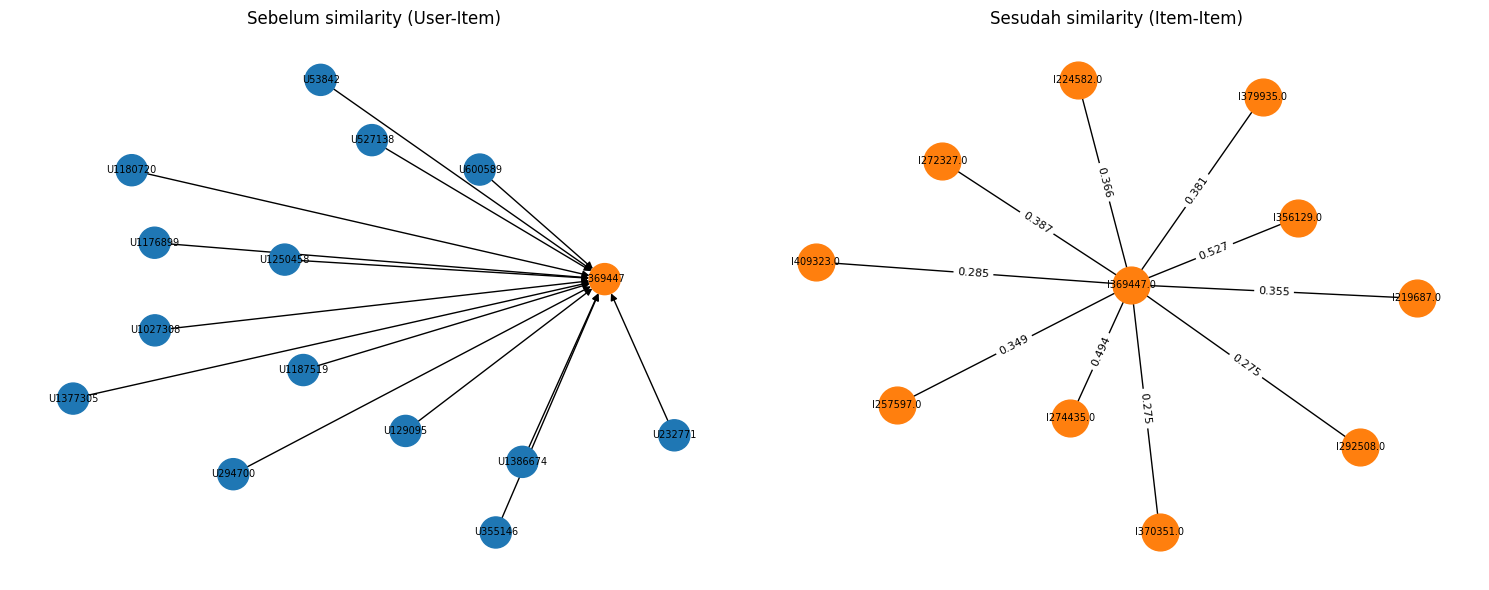

In [29]:
def draw_before_after(ref, n_users=15, n_sim=10): #visualisasi graf
    before = run("""
        MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: $ref})
        RETURN v.visitorId AS u, i.itemId AS i, type(r) AS rel LIMIT $n
    """, ref=ref, n=n_users) #mengambil maksimal 15 interaksi user ke item acuan beserta jenis relasinya

    after = run("""
        MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]-(b:Item)
        RETURN a.itemId AS a, b.itemId AS b, s.score AS score
        ORDER BY s.score DESC LIMIT $n
    """, ref=ref, n=n_sim) #mengambil 10 item paling mirip dengan item acuan beserta nilai cosinenya

    fig, ax = plt.subplots(1, 2, figsize=(15, 6))

    #graf sebelum
    G1 = nx.DiGraph()
    for _, r in before.iterrows():
        G1.add_edge(f"U{r.u}", f"I{r.i}", label=r.rel)
    pos1 = nx.spring_layout(G1, seed=42)
    colors1 = ["tab:orange" if n.startswith("I") else "tab:blue" for n in G1]
    nx.draw(G1, pos1, ax=ax[0], node_color=colors1, node_size=500, font_size=7,
            with_labels=True, arrows=True)
    ax[0].set_title("Sebelum similarity (User-Item)")

    #sesudah, tanpa arah karena cosine simetris
    G2 = nx.Graph()
    for _, r in after.iterrows():
        G2.add_edge(f"I{r.a}", f"I{r.b}", weight=round(r.score, 3))
    pos2 = nx.spring_layout(G2, seed=42)
    nx.draw(G2, pos2, ax=ax[1], node_color="tab:orange", node_size=700, font_size=7,
            with_labels=True)
    nx.draw_networkx_edge_labels(G2, pos2, ax=ax[1],
        edge_labels=nx.get_edge_attributes(G2, "weight"), font_size=8)
    ax[1].set_title("Sesudah similarity (Item-Item)")

    plt.tight_layout()
    plt.savefig("images/sebelum_sesudah_similarity.png", dpi=150)
    plt.show()

draw_before_after(ref_item)

Pada kondisi sebelum similarity, item acuan 369447 hanya terhubung dengan user melalui relasi user-item, sehingga graf berbentuk bintang bipartit tanpa informasi kemiripan antar item. Yang tergambar hanya 15 user sebagai sampel, karena item acuan merupakan item dengan user terbanyak. Pada kondisi sesudah similarity, muncul relasi "SIMILAR_TO" yang menghubungkan item acuan dengan item-item lain beserta nilai cosine pada setiap sisi, dan node user tidak lagi terlibat. 10 item dengan kemiripan tertinggi bernilai cosine sekitar 0,275 sampai 0,527, dengan item 356129 sebagai yang paling mirip (0,527), sesuai output No. 7. Perhitungan similarity menambahkan hubungan antar item pada graf, sehingga graf dapat langsung digunakan untuk rekomendasi berbasis item.

## 2.2 Analytics
Berdasarkan analisis no. 6, rekomendasi dibangun dari proyeksi item-item dengan pendekatan item-based K-Nearest Neighbors (KNN). Setiap item diwakili oleh k = 5 tetangga terdekat, yaitu lima item lain dengan nilai cosine similarity tertinggi.

Sebanyak 41.377 dari 78.171 item memiliki minimal satu tetangga. Sisanya, tidak memiliki tetangga karena user yang mengaksesnya tidak mengakses item lain, sehingga tidak ada kemiripan yang dapat dihitung. Item tanpa tetangga tidak dapat menjadi sumber rekomendasi.

In [30]:
K = 5 #jumlah tetangga terdekat
Xi = normalize(XT) #membagi tiap vektor item dengan panjangnya
XiT = Xi.T.tocsc() #transpose matriks

def topk_cosine(Xi, XiT, k=5, block=500):
    neigh = {} #untuk menyimpan tetangga tiap item
    for s in tqdm(range(0, Xi.shape[0], block), desc="Cosine top-k"): 
        S = (Xi[s:s+block] @ XiT).tocsr()
        for r in range(S.shape[0]):
            a, b = S.indptr[r], S.indptr[r+1]
            idx, val = S.indices[a:b], S.data[a:b] #mengambil nomor item tetangga dan nilai cosinenya
            m = idx != (s + r) 
            idx, val = idx[m], val[m] #membuang item itu sendiri
            if len(val) == 0: #melewati item yang tidak punya tetangga
                continue
            top = np.argsort(-val)[:k]
            neigh[s + r] = [(int(idx[t]), float(val[t])) for t in top] #menyimpan 5 pasangan untuk item itu
    return neigh

neigh = topk_cosine(Xi, XiT, k=K)
print("Item yang punya tetangga:", len(neigh))

Cosine top-k: 100%|██████████| 157/157 [00:04<00:00, 33.55it/s]

Item yang punya tetangga: 41377


### 2.2 No. 1. Pemilihan user acak dan rekomendasi KNN

Kandidat adalah user yang muncul pada P1 dan P2, yaitu 4.179 user. Kandidat diacak dengan "np.random.default_rng(42)", lalu dipilih user pertama yang (1) memiliki minimal satu item relevan, yaitu item yang muncul di P2 dan belum pernah muncul di P1, dan (2) menghasilkan lima rekomendasi. User tanpa item relevan tidak dipilih karena Hit@5 dan NDCG@5 tidak bermakna baginya. Karena seed tetap dan urutan kandidat terurut, proses ini menghasilkan user yang sama pada setiap eksekusi.

User terpilih: 458516. Pada P1, user ini mengakses dua item: 323381 dan 419225.

### 1a. Skrip rekomendasi KNN 

Dengan penjumlahan pada semua item i yang pernah diakses user dan j adalah salah satu dari lima tetangga terdekat item i. Item yang sudah pernah diakses user dikeluarkan dari kandidat, lalu lima item dengan skor tertinggi menjadi rekomendasi (fungsi "recommend"). Karena user hanya mengakses dua item, kandidat berasal dari paling banyak sepuluh tetangga.

### Top-5 rekomendasi

| Peringkat | Item | Skor |
|---|---|---|
| 1 | 425951 | 0,7909 |
| 2 | 438484 | 0,5392 |
| 3 | 58086 | 0,4027 |
| 4 | 211561 | 0,3920 |
| 5 | 373212 | 0,3797 |

Item 425951 memiliki skor jauh di atas yang lain, sehingga paling kuat direkomendasikan.

### 1b. Tiga item yang diiklankan (k = 5) 
Tiga item yang diiklankan adalah 425951, 438484, dan 58086, yaitu tiga item dengan skor tertinggi dari top-5.

In [31]:
SEED = 42
rng = np.random.default_rng(SEED) #membuat pengacak

ids_item = np.asarray(i_idx) #id kolom asli menurut nomor kolom matriks
u_pos = {u: k for k, u in enumerate(u_idx)}
p2_items = p2.groupby("visitorid")["itemid"].apply(lambda s: {int(x) for x in s}).to_dict() #kamus dari user ke himpunan item yang diakses di p2

def item_terlihat(uid): #item yang sudah diakses user di p1
    return {int(x) for x in ids_item[X[u_pos[uid]].indices]}

def item_relevan(uid): #item di p2 yang belum pernah muncul di p1
    return p2_items[uid] - item_terlihat(uid)

def recommend(user_id, neigh, topn=5): #membuat rekomendasi
    row = X[u_pos[user_id]]
    seen = set(row.indices)
    scores = defaultdict(float)
    for c, w in zip(row.indices, row.data):
        for j, s in neigh.get(c, []): #k=5 tetangga terdekat dari tiap item user
            if j not in seen: #tidak rekomendasikan yang sudah pernah diakses
                scores[j] += w * s # skor = bobot interaksi x cosine
    ranked = sorted(scores.items(), key=lambda t: -t[1])[:topn] #mengambil 5 teratas
    return [int(ids_item[j]) for j, _ in ranked], {int(ids_item[j]): round(v, 4) for j, v in ranked}

kandidat = np.intersect1d(np.asarray(u_idx), np.array(list(p2_items.keys()))) #user yang muncul di p1 dan p2
print("Jumlah user kandidat (ada di P1 dan P2):", len(kandidat))

#ambil user pertama yang punya item relevan dan menghasilkan 5 rekomendasi
target = None
for uid in rng.permutation(kandidat):
    uid = int(uid)
    if item_relevan(uid):
        rec5, rec_scores = recommend(uid, neigh, topn=5)
        if len(rec5) == 5:
            target = uid
            break

print("User terpilih:", target)
print("Item di P1:", sorted(item_terlihat(target)))
print("Top-5 rekomendasi:", rec5)
print("Skor:", rec_scores)
print("3 item yang diiklankan (k=5):", rec5[:3])

Jumlah user kandidat (ada di P1 dan P2): 4179
User terpilih: 458516
Item di P1: [323381, 419225]
Top-5 rekomendasi: [425951, 438484, 58086, 211561, 373212]
Skor: {425951: np.float64(0.7909), 438484: np.float64(0.5392), 58086: np.float64(0.4027), 211561: np.float64(0.392), 373212: np.float64(0.3797)}
3 item yang diiklankan (k=5): [425951, 438484, 58086]


### No. 2. Evaluasi rekomendasi: Hit@5 dan NDCG@5

Item relevan adalah item yang diakses user pada P2 dan belum pernah muncul pada P1. Evaluasi memakai top-5 dari no. 1 (tiga teratas di antaranya adalah item yang diiklankan).
- Hit@5 = 1 jika minimal satu item relevan berada pada top-5, selain itu 0.
- DCG@5 = Item relevan di posisi 1 menyumbang 1, di posisi 2 menyumbang 1/log₂3 ≈ 0,631, dan seterusnya mengecil.
- IDCG@5 = DCG pada urutan ideal (semua item relevan di posisi teratas).
- NDCG@5 = DCG@5 / IDCG@5, bernilai 0 sampai 1.

## Hasil untuk user 458516:

| Komponen | Nilai |
|---|---|
| Item relevan | 75358, 144042 (jumlah: 2) |
| Top-5 rekomendasi | 425951, 438484, 58086, 211561, 373212 |
| Posisi hit | tidak ada |
| Hit@5 | 0 |
| NDCG@5 | 0 |

Tidak ada item relevan pada top-5, sehingga DCG = 0 dan kedua metrik bernilai 0.

In [33]:
relevan = item_relevan(target) #item relevanuntuk user terpilih

def hit_at_k(rec, rel, k=5): #fungsi HIT@K
    return int(any(x in rel for x in rec[:k])) #bernilai 1 kalau minimal satu rekomendasi ada di item relevan, selain itu 0

def ndcg_at_k(rec, rel, k=5): #fungsi NDCG@K
    dcg = sum(1 / np.log2(p + 2) for p, x in enumerate(rec[:k]) if x in rel)
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(rel), k))) #DCG pada urutanideal, semua item relevan di posisi teratas
    return dcg / idcg if idcg > 0 else 0.0

print("Item relevan (muncul di P2, belum ada di P1):", sorted(relevan))
print("Top-5 rekomendasi:", rec5)
print("Posisi hit:", [p + 1 for p, x in enumerate(rec5) if x in relevan])
print("Hit@5  =", hit_at_k(rec5, relevan))
print("NDCG@5 =", round(ndcg_at_k(rec5, relevan), 4))

Item relevan (muncul di P2, belum ada di P1): [75358, 144042]
Top-5 rekomendasi: [425951, 438484, 58086, 211561, 373212]
Posisi hit: []
Hit@5  = 0
NDCG@5 = 0.0


### Evaluasi tambahan

Untuk gambaran yang lebih representatif, rekomendasi KNN dievaluasi pada 300 user acak yang diambil dari kandidat. Sebanyak 258 user memiliki item relevan dan dievaluasi, sedangkan 42 user lainnya dilewati karena tidak memiliki item relevan. Sebagai pembanding (baseline) dipakai rekomendasi lima item terpopuler (jumlah user terbanyak) yang belum pernah diakses user, pada sampel yang sama.

| Metode | Rata-rata Hit@5 | Rata-rata NDCG@5 |
|---|---|---|
| KNN item (k = 5) | 0,0116 | 0,0088 |
| Baseline item terpopuler | 0,0000 | 0,0000 |

- Rata-rata Hit@5 sebesar 0,0116 berarti sekitar 3 dari 258 user (0,0116 × 258 = 2,9928) menerima minimal satu rekomendasi yang tepat. Rata-rata NDCG@5 (0,0088) lebih kecil daripada Hit@5 karena hit yang terjadi tidak selalu berada pada posisi pertama sehingga mendapat diskon posisi.
- KNN item lebih baik daripada baseline populer, yang tidak menghasilkan satu hit pun. Artinya informasi kemiripan antar item memberi sinyal yang tidak didapat dari popularitas saja.
- Perbedaan tersebut bersandar pada hanya sekitar tiga user yang mengalami hit, sehingga belum cukup kuat untuk menyimpulkan keunggulan secara meyakinkan.
- Nilai yang rendah secara umum wajar karena data e-commerce sangat sparse, item relevan hanya dihitung bila baru (belum pernah diakses di P1), ruang kandidat 78.171 item sedangkan rekomendasi hanya lima, hanya 41.377 item yang memiliki tetangga, dan terdapat jarak waktu satu bulan antara P1 dan P2.

### Kesimpulan
Pada user terpilih, Hit@5 = 0 dan NDCG@5 = 0. Pada 258 user, rata-rata Hit@5 = 0,0116 dan NDCG@5 = 0,0088, lebih tinggi daripada baseline populer meskipun nilainya kecil.

In [34]:
rng2 = np.random.default_rng(SEED)
sampel = rng2.choice(kandidat, size=min(300, len(kandidat)), replace=False) #memilih 300 user acak tanpa pengulangan

hits, ndcgs = [], [] #daftar nilai per user
for uid in tqdm(sampel, desc="Evaluasi"):
    uid = int(uid)
    rel = item_relevan(uid) #item relevan user itu
    if not rel: #melewati user tanpa item relevan
        continue
    rec, _ = recommend(uid, neigh, topn=5)
    hits.append(hit_at_k(rec, rel))
    ndcgs.append(ndcg_at_k(rec, rel))

print(f"Jumlah user dievaluasi: {len(hits)}")
print(f"Rata-rata Hit@5 = {np.mean(hits):.4f}")
print(f"Rata-rata NDCG@5 = {np.mean(ndcgs):.4f}")

Evaluasi: 100%|██████████| 300/300 [00:00<00:00, 1245.58it/s]

Jumlah user dievaluasi: 258
Rata-rata Hit@5 = 0.0116
Rata-rata NDCG@5 = 0.0088


In [35]:
terlihat = item_terlihat(target) #item yang sudah dilihat user terpilih pada p1

print("Item di P1 user:", sorted(terlihat))
print("Item relevan:", sorted(relevan), "| jumlah:", len(relevan))
print("Item P2 user (semua):", sorted(p2_items[target]))
print("Item relevan ada di vocabulary P1 (punya vektor)",[int(x) in set(map(int, ids_item)) for x in relevan])

Item di P1 user: [323381, 419225]
Item relevan: [75358, 144042] | jumlah: 2
Item P2 user (semua): [75358, 144042]
Item relevan ada di vocabulary P1 (punya vektor) [True, False]


In [36]:
populer = np.asarray((XT != 0).sum(axis=1)).ravel() #jumlah user per item sebagai ukuran popularitas
urut = np.argsort(-populer) #urutan item dari yang terpopuler

hits_pop, ndcgs_pop = [], [] #dict hasil pembanding
for uid in sampel:
    uid = int(uid)
    rel = item_relevan(uid)
    if not rel:
        continue
    seen = item_terlihat(uid)
    rec_pop = []
    for j in urut: #menelusuri item dari terpopuler
        it = int(ids_item[j])
        if it not in seen:
            rec_pop.append(it)
        if len(rec_pop) == 5:
            break
    hits_pop.append(hit_at_k(rec_pop, rel))
    ndcgs_pop.append(ndcg_at_k(rec_pop, rel))

print(f"Populer Hit@5 = {np.mean(hits_pop):.4f} | NDCG@5 = {np.mean(ndcgs_pop):.4f}")
print(f"KNN item Hit@5 = {np.mean(hits):.4f} | NDCG@5 = {np.mean(ndcgs):.4f}")

Populer Hit@5 = 0.0000 | NDCG@5 = 0.0000
KNN item Hit@5 = 0.0116 | NDCG@5 = 0.0088


In [37]:
vocab = set(map(int, ids_item)) #item mana yang tidak punya vektor
for x in sorted(relevan):
    print(x, "punya vektor di P1:", x in vocab)

75358 punya vektor di P1: False
144042 punya vektor di P1: True
